In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


# Portfolio Optimization & Risk Analysis
### A Mean–Variance Optimization Approach Using Exchange-Traded Funds (ETFs)

---

## 1. Introduction

### 1.1 Project Overview

Portfolio optimization is a fundamental problem in quantitative finance. It consists of allocating capital across different financial assets to achieve a desirable balance between **expected return and investment risk**.

According to **Modern Portfolio Theory (MPT)**, introduced by Harry Markowitz, diversification can reduce portfolio risk by combining assets whose returns are not perfectly correlated.

This project applies the principles of **mean–variance portfolio optimization** to a selection of 11 Exchange-Traded Funds (ETFs), representing different economic sectors and gold.

### 1.2 Project Objectives

The main objectives are to:

1. Analyze historical ETF prices, returns, volatility, and correlations.
2. Investigate the benefits of portfolio diversification.
3. Construct and visualize the **Efficient Frontier**.
4. Determine optimal portfolio allocations using numerical optimization.
5. Examine the impact of imposing a **30% maximum allocation constraint** per asset.
6. Compare optimized portfolios against a simple **Equal-Weight (1/N)** strategy.
7. Evaluate the strategies using **out-of-sample performance and risk metrics**.

### 1.3 Data and Methodology

Historical market data are retrieved from **Yahoo Finance** using the `yfinance` Python library.

- **Assets:** 11 ETFs covering multiple sectors and gold.
- **Data frequency:** Daily adjusted closing prices.
- **Full observation period:** January 2016 – December 2025.
- **Training period:** 2016–2021.
- **Testing period:** 2022–2025.
- **Optimization algorithm:** Sequential Least Squares Programming (SLSQP).
- **Risk-free rate proxy:** 3-month U.S. Treasury yield (FRED).

Five portfolio allocation strategies are evaluated:

| Strategy | Description |
|---|---|
| Equal Weight (1/N) | Capital distributed equally across all assets |
| Global Minimum Variance (GMV) | Minimizes portfolio variance |
| GMV Capped | Minimizes variance with a 30% weight limit |
| Maximum Sharpe Ratio | Maximizes expected risk-adjusted return |
| Maximum Sharpe Capped | Maximizes the Sharpe ratio with a 30% weight limit |

The optimized weights are estimated using only the training data. Their performance is subsequently evaluated on the testing period, using an initial investment of **$10,000** and monthly portfolio rebalancing.

### 1.4 Central Research Question

> **Can mean–variance optimization produce portfolios with better out-of-sample risk-adjusted performance than a simple equal-weight allocation, and how do diversification constraints affect the results?**

---


In [2]:
import yfinance as yf

tickers = [
    "IYW",  # Technology
    "MOO",  # Agriculture
    "XLP",  # Consumer Staples
    "XLV",  # Healthcare
    "XLE",  # Energy
    "XLF",  # Financials
    "XLI",  # Industrials
    "XLY",  # Consumer Discretionary
    "XLU",  # Utilities
    "XLB",  # Materials
    "GLD"   # Gold
]

prices = yf.download(
    tickers,
    start="2016-01-01",
    end="2026-01-01",
    auto_adjust=True,
    threads=False,
    timeout=30
)["Close"]

[*********************100%***********************]  11 of 11 completed



## 2. Data Collection

### 2.1 Asset Selection

The portfolio consists of **11 Exchange-Traded Funds (ETFs)** representing different sectors of the economy, alongside gold as an alternative asset.

The selection aims to provide exposure to multiple industries with potentially different return patterns and risk characteristics, allowing us to investigate the benefits of diversification.

### 2.2 Data Source

Historical market data are retrieved from **Yahoo Finance** using the Python library `yfinance`.

The dataset covers the period from **January 1, 2016, to December 31, 2025**, at a daily frequency.

We use **adjusted closing prices**, accounting for corporate actions such as stock splits and distributions. This provides a more appropriate basis for analyzing historical investment returns than unadjusted closing prices.

### 2.3 Data Structure

The resulting dataset is organized as a DataFrame:

- **Rows:** Trading dates.
- **Columns:** The 11 selected ETFs.
- **Values:** Daily adjusted closing prices in USD.

Before proceeding with the financial analysis, we inspect the dataset for missing values, duplicate dates, data types, and descriptive statistics to verify its consistency and quality.


In [43]:

# 1. Dimensions
print("Shape:", prices.shape)

# 2. First and last 5 rows
display(prices.head())
display(prices.tail())

# 3. General information (data types, non-null counts, memory usage)
prices.info()

# 4. Missing values
print("\nMissing values per ETF:")
print(prices.isna().sum())

# 5. Duplicate dates
print("\nDuplicate dates:", prices.index.duplicated().sum())

# 6. Date range
print("\nFirst date:", prices.index.min())
print("Last date:", prices.index.max())

# 7. Descriptive statistics
display(prices.describe())

Shape: (2514, 11)


Ticker,GLD,IYW,MOO,XLB,XLE,XLF,XLI,XLP,XLU,XLV,XLY
Date,,,,,,,,,,,
2016-01-04,102.889999,24.710403,37.654270,17.274632,19.695807,15.568295,43.451385,37.446342,15.380111,59.149158,34.277603
2016-01-05,103.180000,24.586138,37.621452,17.266544,19.770933,15.628243,43.567707,37.686707,15.490510,59.433468,34.233002
2016-01-06,104.669998,24.271984,36.883137,16.813866,19.009882,15.388428,42.894745,37.559017,15.462022,58.948444,33.898338
2016-01-07,106.150002,23.474874,36.153023,16.357143,18.546070,14.955420,41.731598,37.108299,15.358754,57.752586,33.202263
2016-01-08,105.680000,23.289665,35.915115,16.191427,18.307627,14.722265,41.307899,36.822861,15.351627,56.882858,32.845284


Ticker,GLD,IYW,MOO,XLB,XLE,XLF,XLI,XLP,XLU,XLV,XLY
Date,,,,,,,,,,,
2025-12-24,411.929993,202.546143,72.730003,45.258759,43.507736,55.056595,156.253265,76.643387,41.934692,153.891876,121.832581
2025-12-26,416.739990,202.745972,73.029999,45.525337,43.341038,54.947922,155.965576,76.751305,41.905304,154.138824,121.295937
2025-12-29,398.600006,201.776794,72.900002,45.160030,43.752880,54.651550,155.628235,76.800362,41.983669,153.901749,120.103348
2025-12-30,398.890015,201.337173,73.220001,45.150154,44.086269,54.513237,155.181808,76.672821,42.081623,153.773331,119.616371
2025-12-31,396.309998,199.508728,72.790001,44.774971,43.841129,54.108192,153.892105,76.211700,41.817146,152.904114,118.672241


<class 'pandas.DataFrame'>
DatetimeIndex: 2514 entries, 2016-01-04 to 2025-12-31
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   GLD     2514 non-null   float64
 1   IYW     2514 non-null   float64
 2   MOO     2514 non-null   float64
 3   XLB     2514 non-null   float64
 4   XLE     2514 non-null   float64
 5   XLF     2514 non-null   float64
 6   XLI     2514 non-null   float64
 7   XLP     2514 non-null   float64
 8   XLU     2514 non-null   float64
 9   XLV     2514 non-null   float64
 10  XLY     2514 non-null   float64
dtypes: float64(11)
memory usage: 235.7 KB

Missing values per ETF:
Ticker
GLD    0
IYW    0
MOO    0
XLB    0
XLE    0
XLF    0
XLI    0
XLP    0
XLU    0
XLV    0
XLY    0
dtype: int64

Duplicate dates: 0

First date: 2016-01-04 00:00:00
Last date: 2025-12-31 00:00:00


Ticker,GLD,IYW,MOO,XLB,XLE,XLF,XLI,XLP,XLU,XLV,XLY
count,2514.000000,2514.000000,2514.000000,2514.000000,2514.000000,2514.000000,2514.000000,2514.000000,2514.000000,2514.000000,2514.000000
mean,171.225776,81.736670,62.827531,31.443862,28.447546,29.734312,85.216077,56.904957,26.790262,101.551393,68.624024
std,60.312700,46.871686,14.376012,8.739125,9.424592,10.195709,29.000441,13.117345,6.827289,29.051139,23.610374
min,102.889999,21.936922,34.381054,15.067804,9.124844,13.096817,39.887215,36.259476,15.323140,53.119663,30.578552
25%,123.195002,42.064903,52.398260,23.830480,21.965873,22.241564,62.995319,43.286911,20.621940,74.636566,48.515138
50%,164.305000,76.345253,64.639599,31.890362,24.194642,27.349751,80.482925,56.682415,26.550691,102.403889,68.782196
75%,182.914993,107.770037,74.341444,39.081354,38.499806,35.209620,98.430691,67.661530,30.656565,126.195591,86.209002
max,416.739990,211.029770,97.136993,47.009773,45.764462,55.056595,156.253265,80.445137,45.161926,156.160507,121.832581


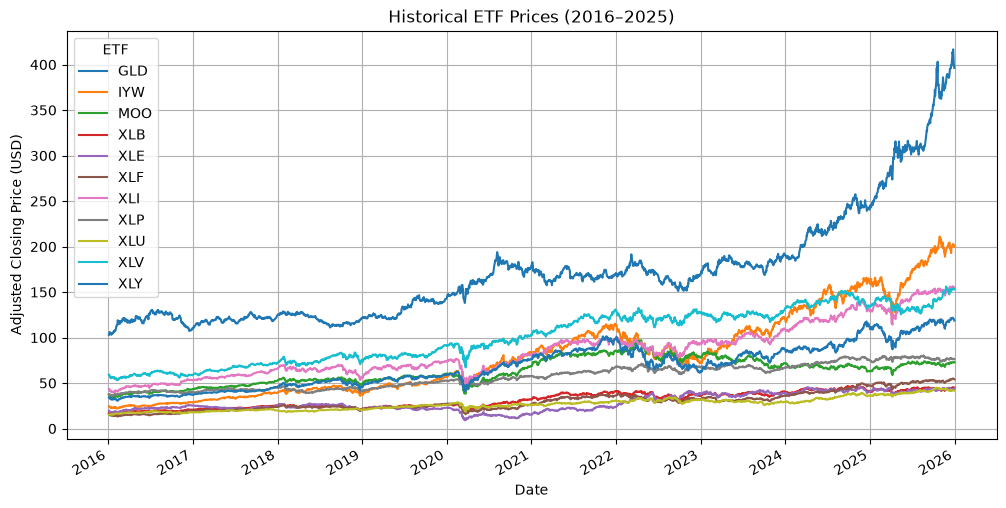

In [44]:
import matplotlib.pyplot as plt

prices.plot(figsize=(12, 6))

plt.title("Historical ETF Prices (2016–2025)")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.grid(True)
plt.legend(title="ETF")
plt.show()

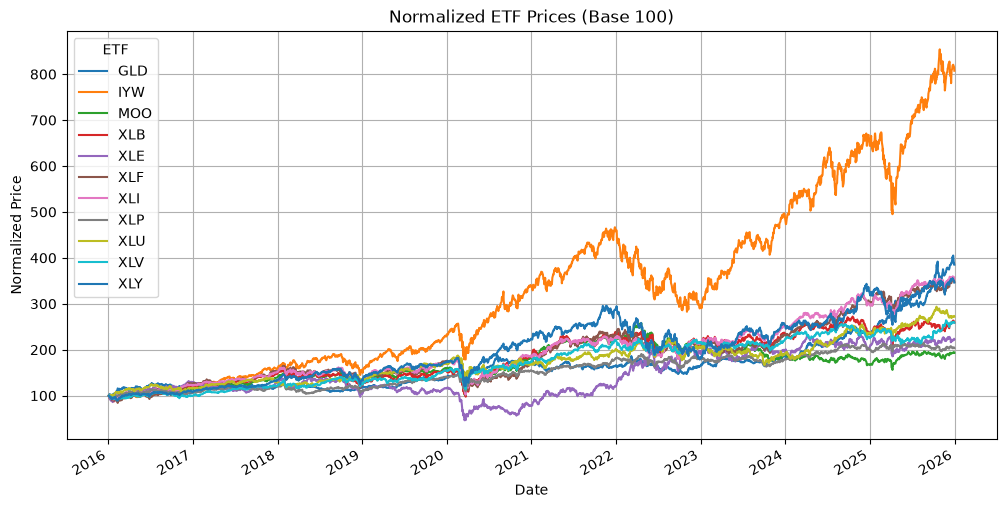

In [45]:
normalized_prices = prices / prices.iloc[0] * 100

normalized_prices.plot(figsize=(12, 6))

plt.title("Normalized ETF Prices (Base 100)")
plt.xlabel("Date")
plt.ylabel("Normalized Price")
plt.grid(True)
plt.legend(title="ETF")
plt.show()

In [46]:
Returns = prices.pct_change(fill_method=None).dropna()

In [47]:
# General information
print("Shape:", Returns.shape)
display(Returns.head())

# Descriptive statistics
display(Returns.describe())

# Missing values
print(Returns.isna().sum())

Shape: (2513, 11)


Ticker,GLD,IYW,MOO,XLB,XLE,XLF,XLI,XLP,XLU,XLV,XLY
Date,,,,,,,,,,,
2016-01-05,0.002819,-0.005029,-0.000872,-0.000468,0.003814,0.003851,0.002677,0.006419,0.007178,0.004807,-0.001301
2016-01-06,0.014441,-0.012778,-0.019625,-0.026217,-0.038493,-0.015345,-0.015446,-0.003388,-0.001839,-0.008161,-0.009776
2016-01-07,0.014140,-0.032841,-0.019795,-0.027163,-0.024398,-0.028139,-0.027116,-0.012000,-0.006679,-0.020287,-0.020534
2016-01-08,-0.004428,-0.007890,-0.006581,-0.010131,-0.012857,-0.015590,-0.010153,-0.007692,-0.000464,-0.015060,-0.010752
2016-01-11,-0.008895,0.005134,-0.007994,-0.016975,-0.021409,0.001357,0.000603,0.009384,0.005335,-0.011908,0.007880


Ticker,GLD,IYW,MOO,XLB,XLE,XLF,XLI,XLP,XLU,XLV,XLY
count,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000,2513.000000
mean,0.000580,0.000955,0.000329,0.000465,0.000496,0.000595,0.000582,0.000325,0.000471,0.000433,0.000590
std,0.009324,0.015726,0.011505,0.013068,0.018758,0.014050,0.012523,0.009223,0.012078,0.010479,0.013832
min,-0.064269,-0.136236,-0.117681,-0.110084,-0.201412,-0.137093,-0.113441,-0.093956,-0.113577,-0.098610,-0.126686
25%,-0.004470,-0.005729,-0.005105,-0.006186,-0.008003,-0.005387,-0.004993,-0.003862,-0.005335,-0.004431,-0.005454
50%,0.000698,0.001657,0.000605,0.000710,0.000694,0.000798,0.000924,0.000527,0.001021,0.000603,0.001248
75%,0.005494,0.008885,0.006358,0.007384,0.009406,0.007342,0.006675,0.005043,0.006533,0.005781,0.007405
max,0.049038,0.135841,0.082914,0.117601,0.160374,0.131566,0.126512,0.085106,0.127934,0.077057,0.108881


Ticker
GLD    0
IYW    0
MOO    0
XLB    0
XLE    0
XLF    0
XLI    0
XLP    0
XLU    0
XLV    0
XLY    0
dtype: int64


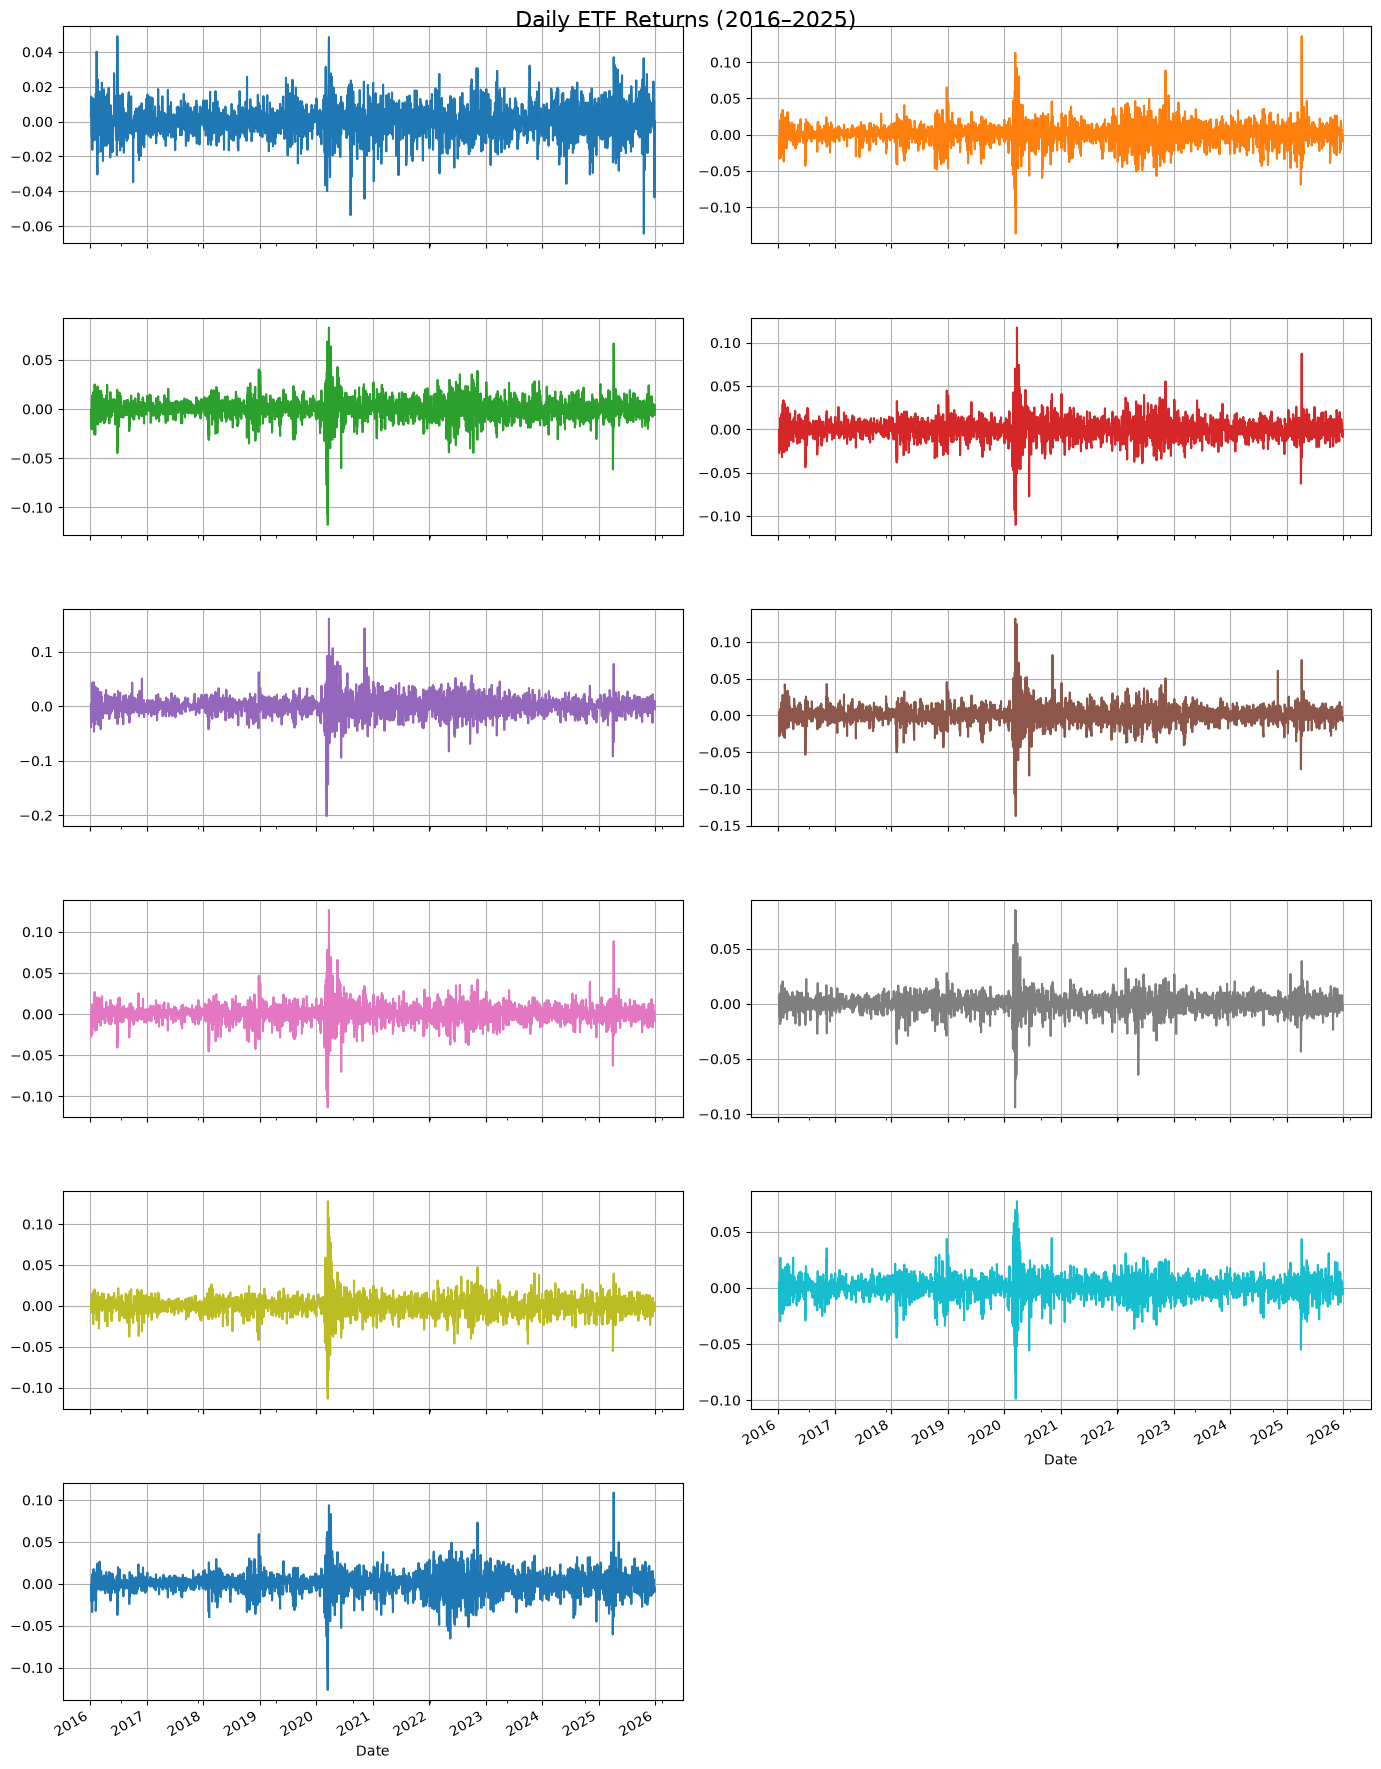

In [48]:
Returns.plot(
    subplots=True,
    figsize=(14, 18),
    layout=(6, 2),
    sharex=True,
    legend=False,
    grid=True
)

plt.suptitle("Daily ETF Returns (2016–2025)", fontsize=16)
plt.tight_layout()
plt.show()

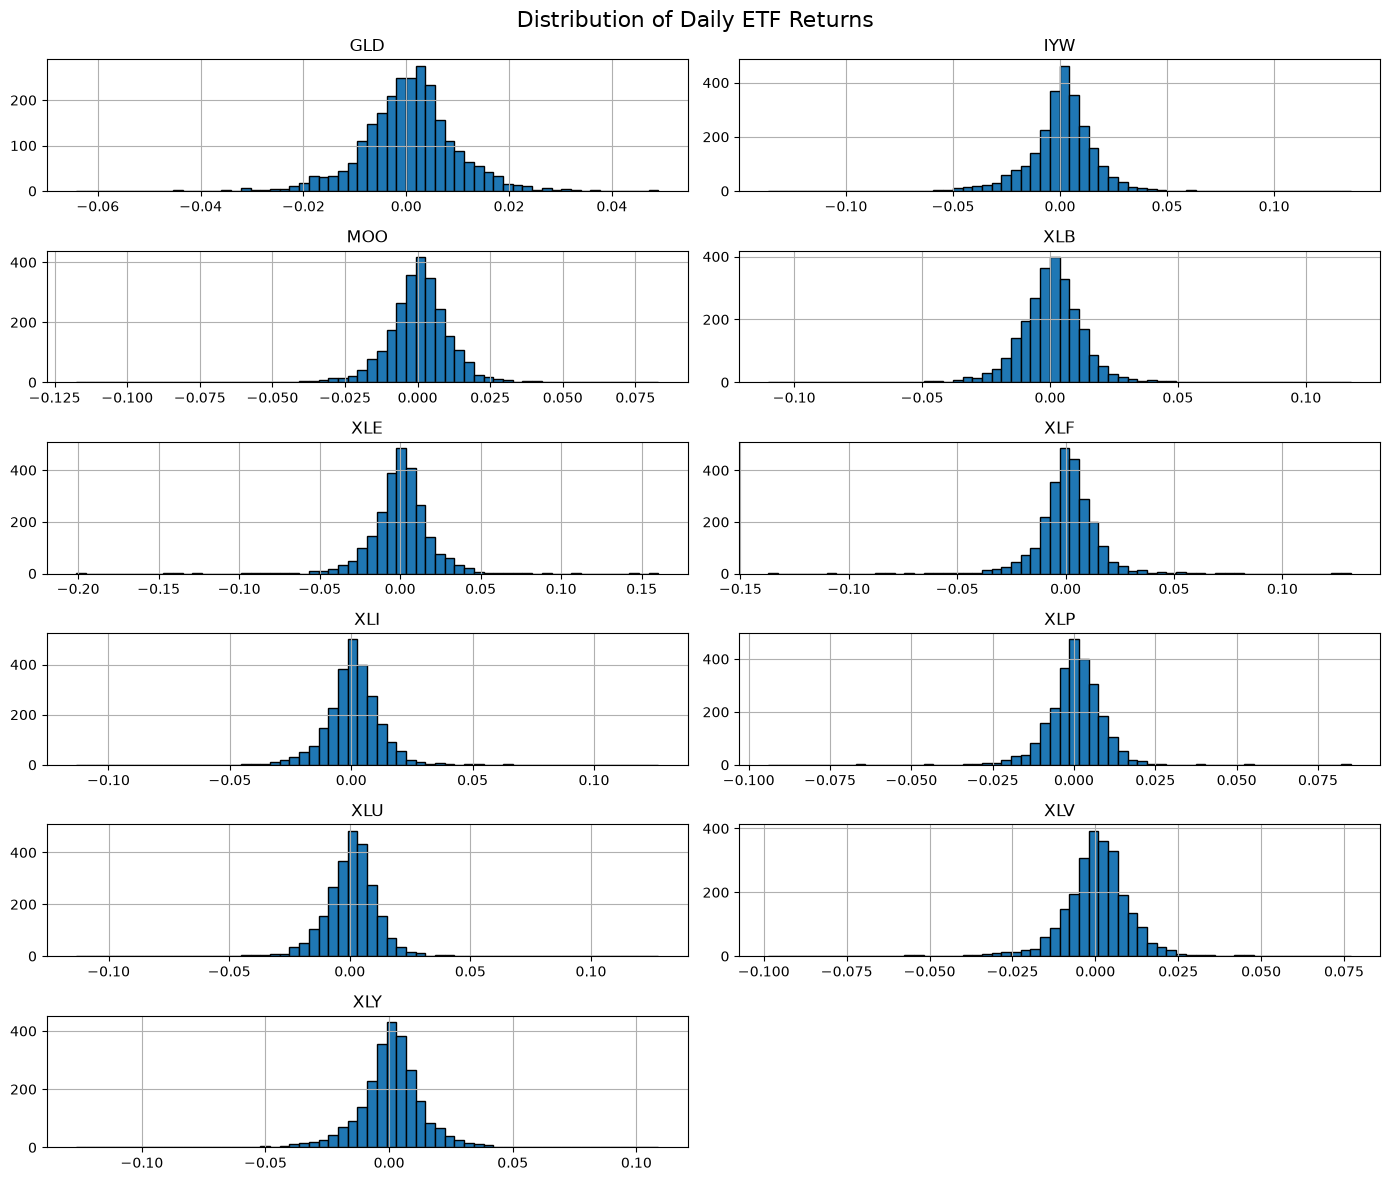

In [49]:
Returns.hist(
    bins=60,
    figsize=(14, 12),
    layout=(6, 2),
    edgecolor="black"
)

plt.suptitle("Distribution of Daily ETF Returns", fontsize=16)
plt.tight_layout()
plt.show()

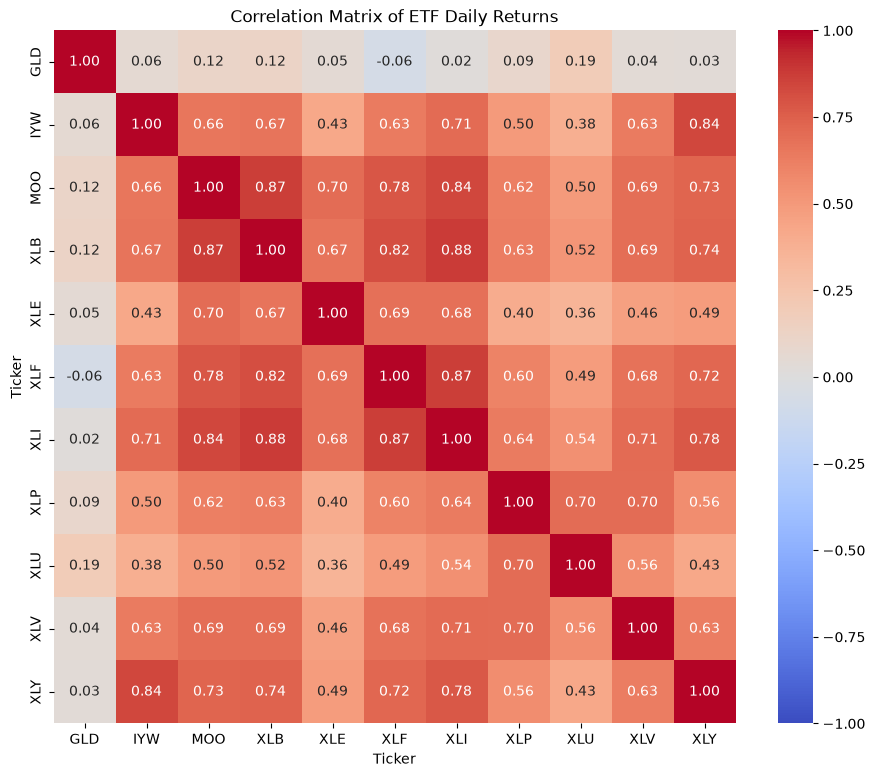

In [50]:
import seaborn as sns

corr_matrix = Returns.corr()

plt.figure(figsize=(11, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Correlation Matrix of ETF Daily Returns")
plt.show()

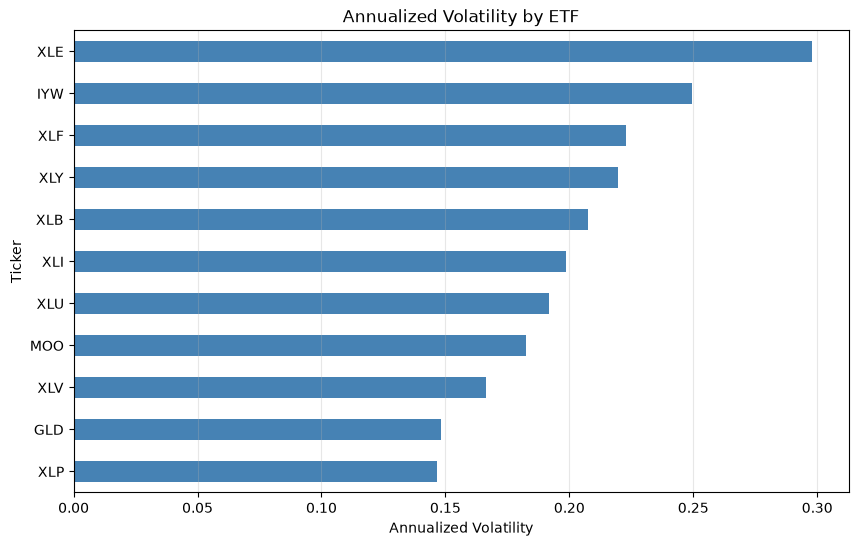

In [51]:
annual_volatility = Returns.std() * (252 ** 0.5)

annual_volatility.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    color="steelblue"
)

plt.title("Annualized Volatility by ETF")
plt.xlabel("Annualized Volatility")
plt.grid(axis="x", alpha=0.3)
plt.show()

In [52]:
train = Returns.loc["2016":"2021"]
test = Returns.loc["2022":"2025"]

In [53]:
print("Training shape:", train.shape)
print("Testing shape:", test.shape)

print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training shape: (1510, 11)
Testing shape: (1003, 11)

Training period: 2016-01-05 00:00:00 to 2021-12-31 00:00:00
Testing period: 2022-01-03 00:00:00 to 2025-12-31 00:00:00


In [54]:
asset_stats = pd.DataFrame({
    "Annual Return": train.mean() * 252,
    "Annual Volatility": train.std() * np.sqrt(252)
})

display(asset_stats)

,Annual Return,Annual Volatility
Ticker,,
GLD,0.094391,0.138807
IYW,0.281562,0.234396
MOO,0.154537,0.186310
XLB,0.168627,0.215921
XLE,0.081926,0.320792
XLF,0.169668,0.243240
XLI,0.159406,0.212739
XLP,0.111453,0.153810
XLU,0.137308,0.200532


In [55]:
cov_matrix = train.cov() * 252

display(cov_matrix)

Ticker,GLD,IYW,MOO,XLB,XLE,XLF,XLI,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,,,
GLD,0.019267,0.000758,0.001029,0.001522,-0.000714,-0.004266,-0.000972,0.001535,0.004405,0.000114,0.000202
IYW,0.000758,0.054941,0.033156,0.035225,0.038482,0.037122,0.035512,0.022268,0.020936,0.030816,0.039518
MOO,0.001029,0.033156,0.034711,0.036042,0.044970,0.037640,0.035055,0.019184,0.019336,0.024678,0.030506
XLB,0.001522,0.035225,0.036042,0.046622,0.051220,0.043876,0.041074,0.021835,0.022778,0.027133,0.033121
XLE,-0.000714,0.038482,0.044970,0.051220,0.102908,0.059630,0.051452,0.023154,0.024499,0.030173,0.038730
XLF,-0.004266,0.037122,0.037640,0.043876,0.059630,0.059166,0.045880,0.023346,0.023862,0.029795,0.036177
XLI,-0.000972,0.035512,0.035055,0.041074,0.051452,0.045880,0.045258,0.022353,0.023550,0.027677,0.034052
XLP,0.001535,0.022268,0.019184,0.021835,0.023154,0.023346,0.022353,0.023658,0.023090,0.019323,0.019654
XLU,0.004405,0.020936,0.019336,0.022778,0.024499,0.023862,0.023550,0.023090,0.040213,0.020214,0.019437


In [56]:
corr_matrix = train.corr()

display(corr_matrix)

Ticker,GLD,IYW,MOO,XLB,XLE,XLF,XLI,XLP,XLU,XLV,XLY
Ticker,,,,,,,,,,,
GLD,1.000000,0.023302,0.039798,0.050794,-0.016044,-0.126360,-0.032931,0.071886,0.158248,0.004677,0.007406
IYW,0.023302,1.000000,0.759228,0.695990,0.511777,0.651095,0.712159,0.617646,0.445402,0.747326,0.859686
MOO,0.039798,0.759228,1.000000,0.895947,0.752425,0.830573,0.884446,0.669454,0.517547,0.752938,0.834911
XLB,0.050794,0.695990,0.895947,1.000000,0.739467,0.835413,0.894182,0.657478,0.526064,0.714300,0.782175
XLE,-0.016044,0.511777,0.752425,0.739467,1.000000,0.764192,0.753929,0.469261,0.380844,0.534656,0.615629
XLF,-0.126360,0.651095,0.830573,0.835413,0.764192,1.000000,0.886630,0.624010,0.489210,0.696303,0.758393
XLI,-0.032931,0.712159,0.884446,0.894182,0.753929,0.886630,1.000000,0.683130,0.552030,0.739542,0.816189
XLP,0.071886,0.617646,0.669454,0.657478,0.469261,0.624010,0.683130,1.000000,0.748610,0.714132,0.651552
XLU,0.158248,0.445402,0.517547,0.526064,0.380844,0.489210,0.552030,0.748610,1.000000,0.572983,0.494241


In [57]:
# Number of assets and portfolios
n_assets = len(asset_stats)
n_portfolios = 10_000

# Reproducibility
rng = np.random.default_rng(42)

# Generate random weights
weights = rng.dirichlet(
    alpha=np.ones(n_assets),
    size=n_portfolios
)

print("Weights shape:", weights.shape)
print("First portfolio:", weights[0])
print("Sum of weights:", weights[0].sum())

Weights shape: (10000, 11)
First portfolio: [0.1638347  0.15919955 0.16250944 0.01906657 0.00589027 0.09899149
 0.09608172 0.21290502 0.0054035  0.07131785 0.00479988]
Sum of weights: 1.0000000000000002


In [58]:
# Align the ETF ordering
tickers = asset_stats.index

mu = asset_stats.loc[tickers, "Annual Return"].to_numpy()
Sigma = cov_matrix.loc[tickers, tickers].to_numpy()

# Expected annual returns
portfolio_returns = weights @ mu

# Annualized portfolio variances
portfolio_variances = np.einsum(
    "ij,jk,ik->i",
    weights,
    Sigma,
    weights
)

# Annualized portfolio volatilities
portfolio_volatilities = np.sqrt(
    np.maximum(portfolio_variances, 0)
)

In [59]:
portfolios = pd.DataFrame({
    "Expected Return": portfolio_returns,
    "Volatility": portfolio_volatilities
})

display(portfolios.head())

,Expected Return,Volatility
0,0.157135,0.146605
1,0.169669,0.153218
2,0.155023,0.139013
3,0.148070,0.161654
4,0.177745,0.164647


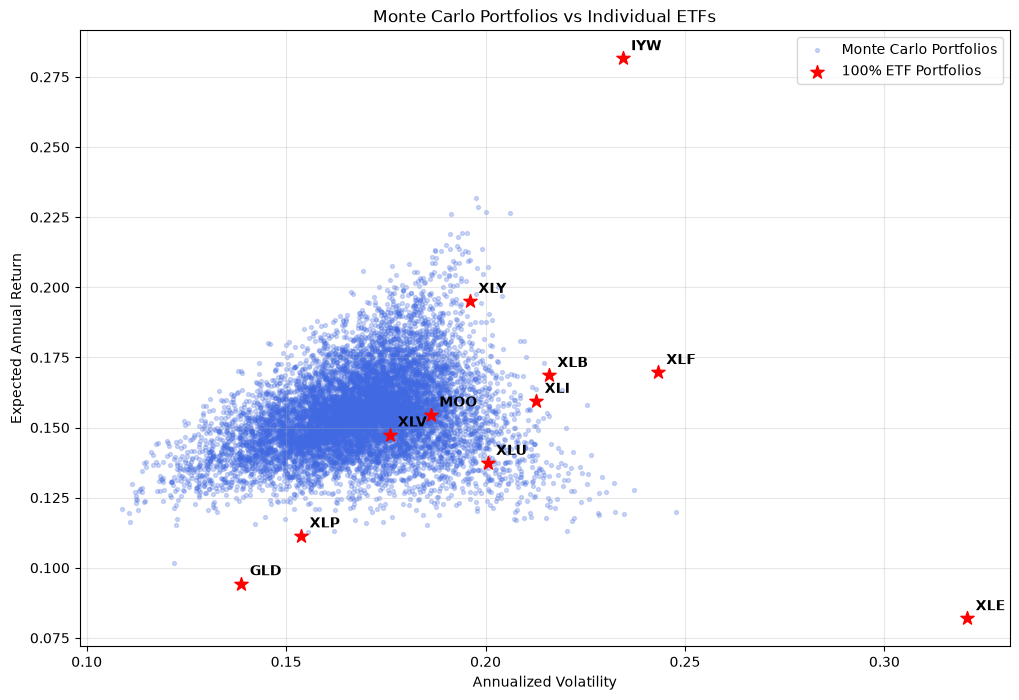

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

# 10,000 random portfolios
plt.scatter(
    portfolio_volatilities,
    portfolio_returns,
    s=8,
    alpha=0.25,
    color="royalblue",
    label="Monte Carlo Portfolios"
)

# Individual ETFs (100% allocation)
plt.scatter(
    asset_stats["Annual Volatility"],
    asset_stats["Annual Return"],
    color="red",
    s=100,
    marker="*",
    label="100% ETF Portfolios",
    zorder=5
)

# Label each ETF
for ticker in asset_stats.index:
    plt.annotate(
        ticker,
        (
            asset_stats.loc[ticker, "Annual Volatility"],
            asset_stats.loc[ticker, "Annual Return"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Monte Carlo Portfolios vs Individual ETFs")
plt.xlabel("Annualized Volatility")
plt.ylabel("Expected Annual Return")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [61]:
from scipy.optimize import minimize

# Objective function
def portfolio_variance(w):
    return w @ Sigma @ w

# Gradient
def gradient(w):
    return 2 * Sigma @ w

# Initial weights
w0 = np.ones(n_assets) / n_assets

# Budget constraint
constraints = {
    "type": "eq",
    "fun": lambda w: np.sum(w) - 1
}

# Long-only bounds
bounds = [(0, 1)] * n_assets

# Optimization
result = minimize(
    fun=portfolio_variance,
    x0=w0,
    jac=gradient,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 1000}
)

print(result.message)

if not result.success:
    raise RuntimeError("GMV optimization failed")

Optimization terminated successfully


In [62]:
gmv_weights = pd.Series(
    result.x,
    index=tickers,
    name="GMV Weight"
)

gmv_variance = result.fun
gmv_volatility = np.sqrt(gmv_variance)
gmv_return = result.x @ mu

display(
    (gmv_weights * 100)
    .sort_values(ascending=False)
    .to_frame("Weight (%)")
)

print(f"Expected annual return: {gmv_return:.2%}")
print(f"Annual volatility: {gmv_volatility:.2%}")
print(f"Sum of weights: {gmv_weights.sum():.8f}")

,Weight (%)
Ticker,
GLD,5.498922e+01
XLP,2.551429e+01
XLV,1.268902e+01
XLF,4.227754e+00
XLY,2.579717e+00
XLB,1.070650e-16
IYW,0.000000e+00
MOO,0.000000e+00
XLE,0.000000e+00


Expected annual return: 11.13%
Annual volatility: 10.40%
Sum of weights: 1.00000000


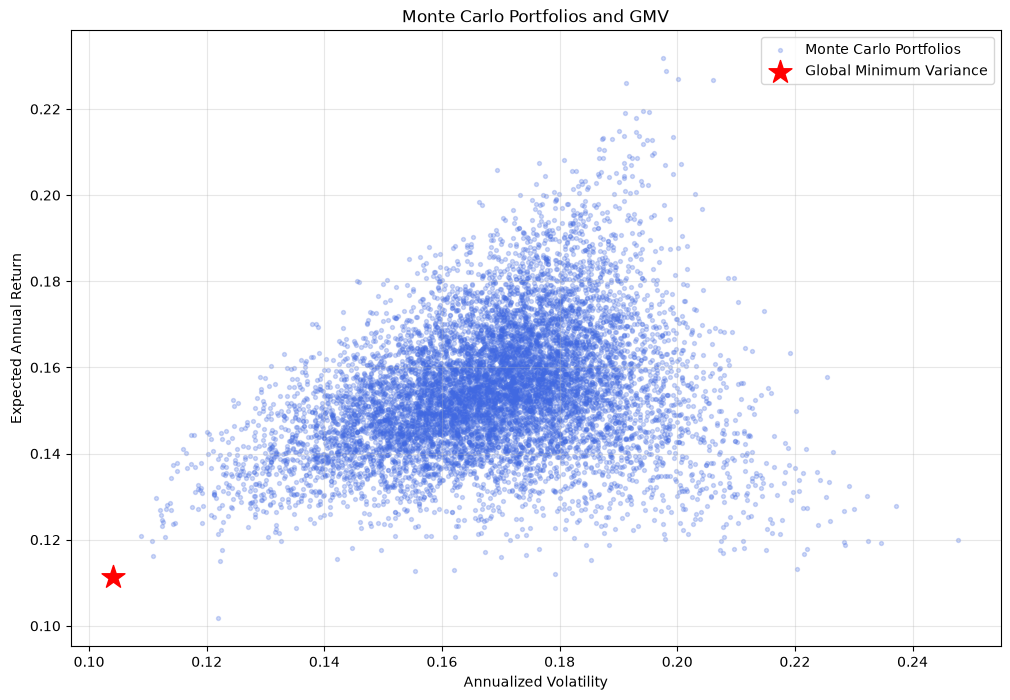

In [63]:
plt.figure(figsize=(12, 8))

plt.scatter(
    portfolio_volatilities,
    portfolio_returns,
    s=8,
    alpha=0.25,
    color="royalblue",
    label="Monte Carlo Portfolios"
)

plt.scatter(
    gmv_volatility,
    gmv_return,
    color="red",
    marker="*",
    s=300,
    label="Global Minimum Variance",
    zorder=5
)

plt.title("Monte Carlo Portfolios and GMV")
plt.xlabel("Annualized Volatility")
plt.ylabel("Expected Annual Return")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [64]:
# 50 target annual returns
target_returns = np.linspace(gmv_return, mu.max(), 50)

frontier_returns = []
frontier_volatilities = []
frontier_weights = []

for r in target_returns:

    # Budget and target-return constraints
    frontier_constraints = [
        {
            "type": "eq",
            "fun": lambda w: np.sum(w) - 1
        },
        {
            "type": "eq",
            "fun": lambda w, target=r: w @ mu - target
        }
    ]

    # Minimize portfolio variance
    solution = minimize(
        fun=portfolio_variance,
        x0=w0,
        jac=gradient,
        method="SLSQP",
        bounds=bounds,
        constraints=frontier_constraints,
        options={"ftol": 1e-12, "maxiter": 1000}
    )

    # Check convergence and constraints
    if not solution.success:
        raise RuntimeError(
            f"Optimization failed for target {r:.4f}: {solution.message}"
        )

    if abs(solution.x.sum() - 1) > 1e-6:
        raise RuntimeError("Budget constraint violated")

    if abs(solution.x @ mu - r) > 1e-6:
        raise RuntimeError("Return constraint violated")

    # Store results
    frontier_returns.append(solution.x @ mu)
    frontier_volatilities.append(np.sqrt(solution.fun))
    frontier_weights.append(solution.x.copy())

In [65]:
frontier = pd.DataFrame({
    "Expected Return": frontier_returns,
    "Volatility": frontier_volatilities
})

display(frontier.head())

,Expected Return,Volatility
0,0.111255,0.104048
1,0.114731,0.104224
2,0.118206,0.104750
3,0.121682,0.105480
4,0.125158,0.106322


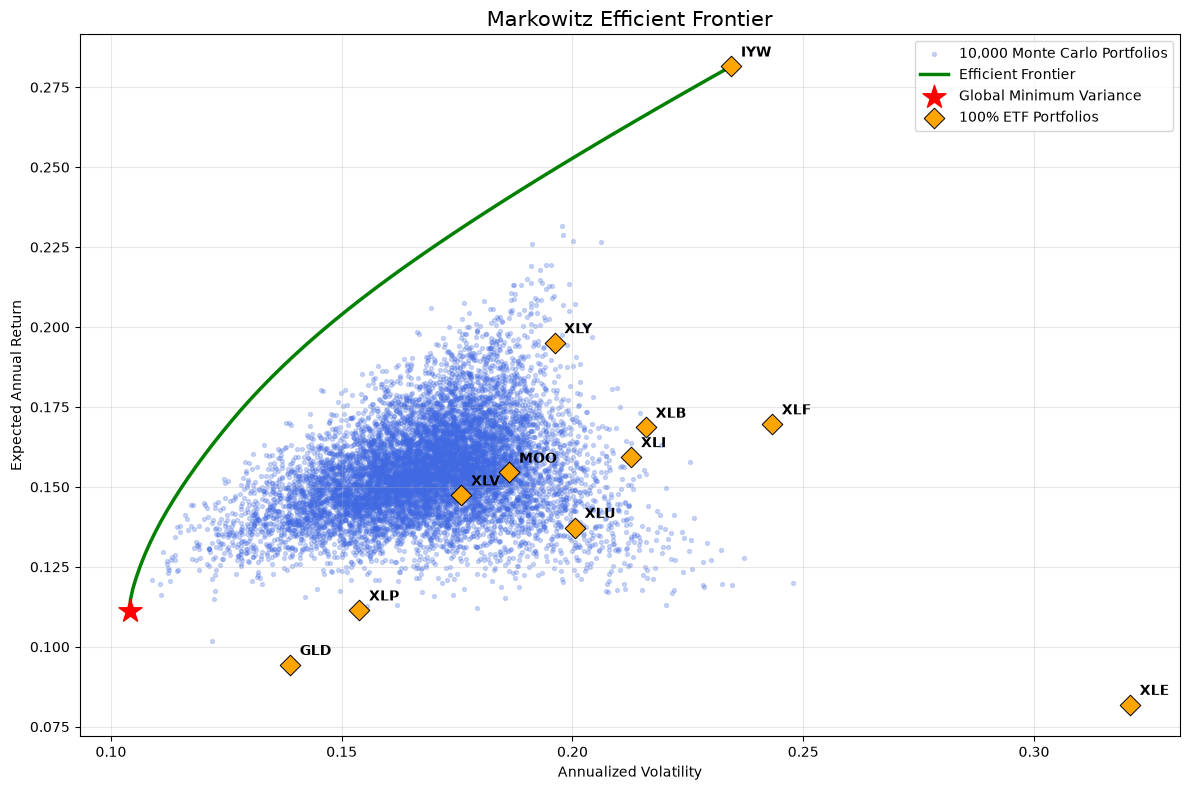

In [66]:
plt.figure(figsize=(12, 8))

# Monte Carlo portfolios
plt.scatter(
    portfolio_volatilities,
    portfolio_returns,
    s=8,
    alpha=0.25,
    color="royalblue",
    label="10,000 Monte Carlo Portfolios"
)

# Efficient frontier
plt.plot(
    frontier["Volatility"],
    frontier["Expected Return"],
    color="green",
    linewidth=2.5,
    label="Efficient Frontier",
    zorder=4
)

# Global minimum-variance portfolio
plt.scatter(
    gmv_volatility,
    gmv_return,
    color="red",
    marker="*",
    s=300,
    label="Global Minimum Variance",
    zorder=6
)

# Individual ETFs (100% allocation)
plt.scatter(
    asset_stats["Annual Volatility"],
    asset_stats["Annual Return"],
    color="orange",
    edgecolor="black",
    linewidth=0.7,
    s=110,
    marker="D",
    label="100% ETF Portfolios",
    zorder=5
)

# Label each ETF
for ticker in asset_stats.index:
    plt.annotate(
        ticker,
        (
            asset_stats.loc[ticker, "Annual Volatility"],
            asset_stats.loc[ticker, "Annual Return"]
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Markowitz Efficient Frontier", fontsize=15)
plt.xlabel("Annualized Volatility")
plt.ylabel("Expected Annual Return")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [67]:
# 3-month US Treasury constant-maturity yield (FRED)
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS3MO"

treasury = pd.read_csv(url, index_col=0, parse_dates=True)

# Convert percentage yields to decimal annual rates
treasury["DGS3MO"] = pd.to_numeric(
    treasury["DGS3MO"], errors="coerce"
) / 100

# Training period only (2016–2021)
rf_train = treasury.loc["2016":"2021", "DGS3MO"].dropna()

# Average annual risk-free rate
rf = rf_train.mean()

print(f"Average risk-free rate (2016–2021): {rf:.4%}")

Average risk-free rate (2016–2021): 0.9568%


In [68]:
# Negative Sharpe ratio (SLSQP minimizes)
def negative_sharpe(w):
    expected_return = w @ mu
    volatility = np.sqrt(w @ Sigma @ w)

    return -(expected_return - rf) / volatility


# Numerical optimization
sharpe_result = minimize(
    fun=negative_sharpe,
    x0=w0,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 1000}
)

if not sharpe_result.success:
    raise RuntimeError(sharpe_result.message)

# Store optimal weights
sharpe_weights = pd.Series(
    sharpe_result.x,
    index=tickers,
    name="Max Sharpe Weight"
)

# Portfolio statistics
sharpe_return = sharpe_result.x @ mu

sharpe_volatility = np.sqrt(
    sharpe_result.x @ Sigma @ sharpe_result.x
)

sharpe_ratio = (
    sharpe_return - rf
) / sharpe_volatility

print("Maximum Sharpe Ratio Portfolio")
print("------------------------------")
print(sharpe_weights.round(4))
print(f"\nExpected annual return: {sharpe_return:.2%}")
print(f"Annualized volatility: {sharpe_volatility:.2%}")
print(f"Sharpe ratio: {sharpe_ratio:.4f}")

Maximum Sharpe Ratio Portfolio
------------------------------
Ticker
GLD    0.4530
IYW    0.5235
MOO    0.0000
XLB    0.0000
XLE    0.0000
XLF    0.0000
XLI    0.0000
XLP    0.0000
XLU    0.0235
XLV    0.0000
XLY    0.0000
Name: Max Sharpe Weight, dtype: float64

Expected annual return: 19.34%
Annualized volatility: 14.14%
Sharpe ratio: 1.2997


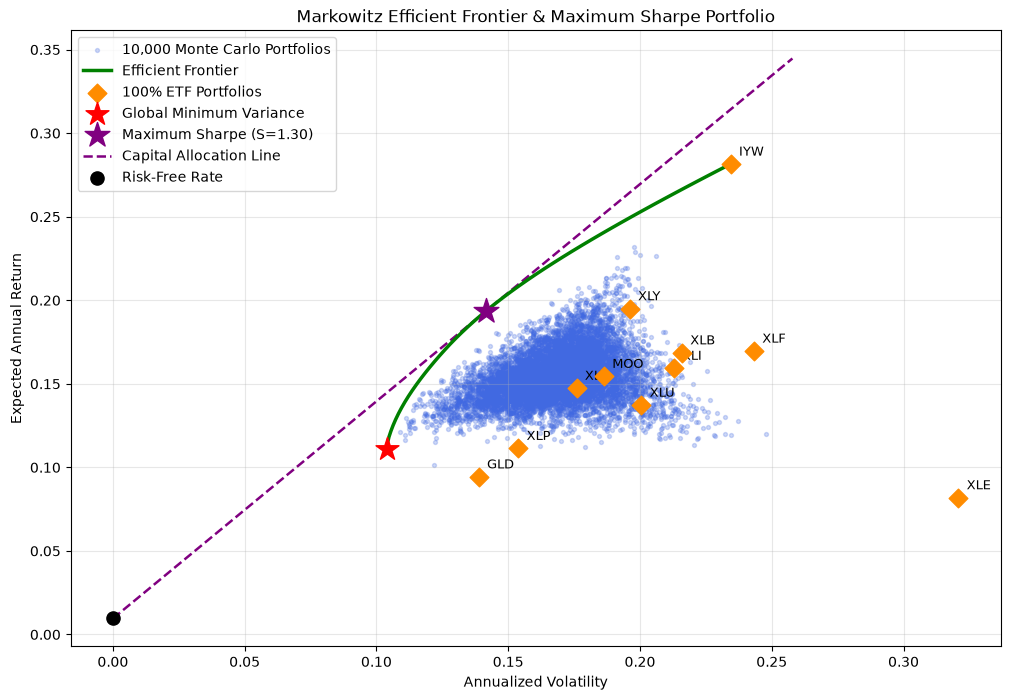

In [69]:
plt.figure(figsize=(12, 8))

# Monte Carlo portfolios
plt.scatter(
    portfolio_volatilities,
    portfolio_returns,
    s=8,
    alpha=0.25,
    color="royalblue",
    label="10,000 Monte Carlo Portfolios"
)

# Efficient frontier
plt.plot(
    frontier["Volatility"],
    frontier["Expected Return"],
    color="green",
    linewidth=2.5,
    label="Efficient Frontier",
    zorder=4
)

# Individual ETFs (100% invested)
plt.scatter(
    asset_stats.loc[tickers, "Annual Volatility"],
    asset_stats.loc[tickers, "Annual Return"],
    color="darkorange",
    marker="D",
    s=90,
    label="100% ETF Portfolios",
    zorder=5
)

for ticker in tickers:
    plt.annotate(
        ticker,
        (
            asset_stats.loc[ticker, "Annual Volatility"],
            asset_stats.loc[ticker, "Annual Return"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

# Global minimum-variance portfolio
plt.scatter(
    gmv_volatility,
    gmv_return,
    color="red",
    marker="*",
    s=300,
    label="Global Minimum Variance",
    zorder=6
)

# Maximum Sharpe portfolio
plt.scatter(
    sharpe_volatility,
    sharpe_return,
    color="purple",
    marker="*",
    s=350,
    label=f"Maximum Sharpe (S={sharpe_ratio:.2f})",
    zorder=7
)

# Capital Allocation Line (CAL)
cal_volatilities = np.linspace(0, max(frontier["Volatility"].max(), sharpe_volatility) * 1.1, 100)
cal_returns = rf + sharpe_ratio * cal_volatilities

plt.plot(
    cal_volatilities,
    cal_returns,
    color="purple",
    linestyle="--",
    linewidth=1.8,
    label="Capital Allocation Line",
    zorder=3
)

# Risk-free asset
plt.scatter(
    0,
    rf,
    color="black",
    marker="o",
    s=90,
    label="Risk-Free Rate",
    zorder=7
)

plt.title("Markowitz Efficient Frontier & Maximum Sharpe Portfolio")
plt.xlabel("Annualized Volatility")
plt.ylabel("Expected Annual Return")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [70]:
# Maximum allocation of 30% per ETF
capped_bounds = [(0, 0.30)] * n_assets

# SLSQP optimization
capped_sharpe_result = minimize(
    fun=negative_sharpe,
    x0=w0,
    method="SLSQP",
    bounds=capped_bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 1000}
)

if not capped_sharpe_result.success:
    raise RuntimeError(capped_sharpe_result.message)

# Store optimized weights
capped_sharpe_weights = pd.Series(
    capped_sharpe_result.x,
    index=tickers,
    name="Capped Max Sharpe"
)

# Portfolio statistics
capped_sharpe_return = capped_sharpe_result.x @ mu

capped_sharpe_volatility = np.sqrt(
    capped_sharpe_result.x @ Sigma @ capped_sharpe_result.x
)

capped_sharpe_ratio = (
    capped_sharpe_return - rf
) / capped_sharpe_volatility

# Display results
display(
    (capped_sharpe_weights * 100)
    .sort_values(ascending=False)
    .to_frame("Weight (%)")
)

print(f"Expected annual return: {capped_sharpe_return:.2%}")
print(f"Annualized volatility: {capped_sharpe_volatility:.2%}")
print(f"Sharpe ratio: {capped_sharpe_ratio:.4f}")

print(f"Sum of weights: {capped_sharpe_weights.sum():.6f}")
print(f"Maximum weight: {capped_sharpe_weights.max():.2%}")

,Weight (%)
Ticker,
IYW,3.000000e+01
GLD,3.000000e+01
XLY,2.366363e+01
XLU,1.171286e+01
XLV,4.623511e+00
XLE,1.464960e-14
XLF,1.401111e-14
XLB,6.976502e-15
XLI,3.978175e-15


Expected annual return: 18.18%
Annualized volatility: 14.04%
Sharpe ratio: 1.2271
Sum of weights: 1.000000
Maximum weight: 30.00%


In [71]:
comparison = pd.DataFrame({
    "Uncapped (%)": sharpe_weights * 100,
    "Capped 30% (%)": capped_sharpe_weights * 100
})

display(comparison.round(2))

print(f"Uncapped Sharpe: {sharpe_ratio:.4f}")
print(f"Capped Sharpe:   {capped_sharpe_ratio:.4f}")

,Uncapped (%),Capped 30% (%)
Ticker,,
GLD,45.30,30.00
IYW,52.35,30.00
MOO,0.00,0.00
XLB,0.00,0.00
XLE,0.00,0.00
XLF,0.00,0.00
XLI,0.00,0.00
XLP,0.00,0.00
XLU,2.35,11.71


Uncapped Sharpe: 1.2997
Capped Sharpe:   1.2271


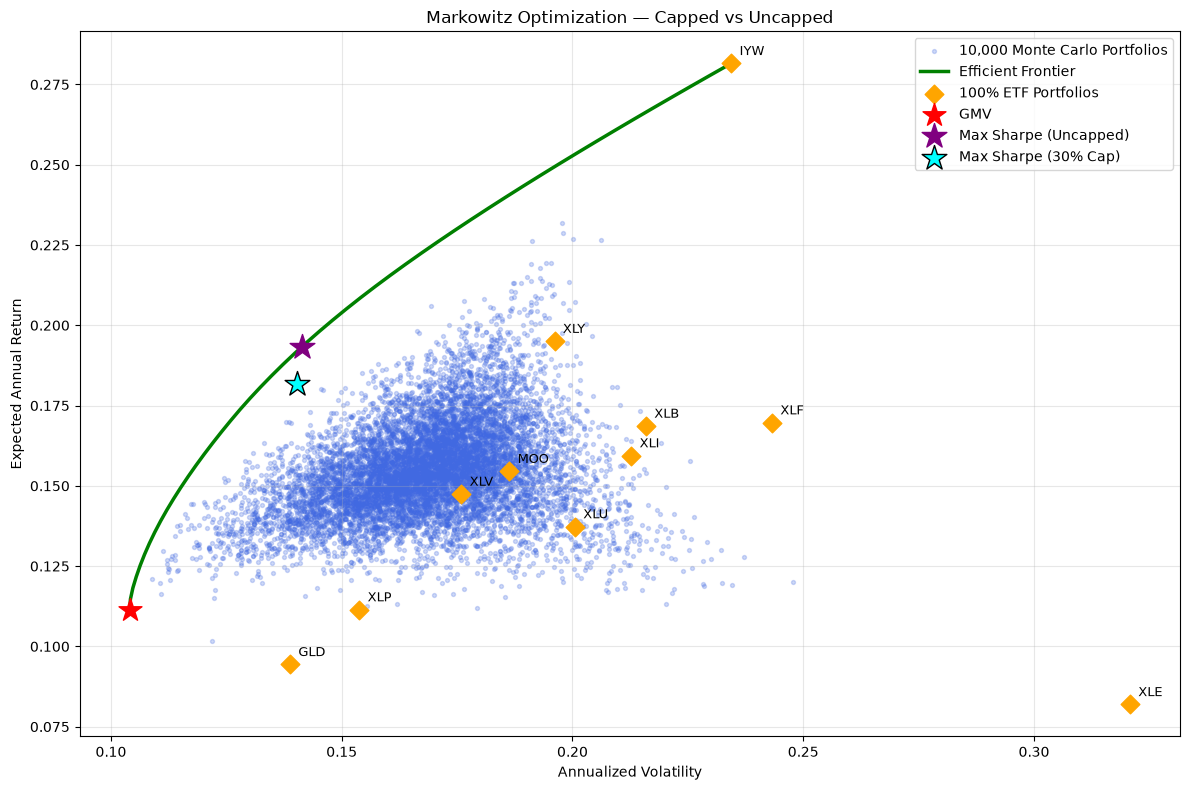

In [72]:
plt.figure(figsize=(12, 8))

# Monte Carlo portfolios
plt.scatter(
    portfolio_volatilities,
    portfolio_returns,
    s=8,
    alpha=0.25,
    color="royalblue",
    label="10,000 Monte Carlo Portfolios"
)

# Original efficient frontier
plt.plot(
    frontier["Volatility"],
    frontier["Expected Return"],
    color="green",
    linewidth=2.5,
    label="Efficient Frontier",
    zorder=4
)

# Individual ETFs
plt.scatter(
    asset_stats["Annual Volatility"],
    asset_stats["Annual Return"],
    color="orange",
    marker="D",
    s=90,
    label="100% ETF Portfolios",
    zorder=5
)

for ticker in asset_stats.index:
    plt.annotate(
        ticker,
        (
            asset_stats.loc[ticker, "Annual Volatility"],
            asset_stats.loc[ticker, "Annual Return"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

# Global minimum variance
plt.scatter(
    gmv_volatility,
    gmv_return,
    color="red",
    marker="*",
    s=300,
    label="GMV",
    zorder=6
)

# Original maximum Sharpe
plt.scatter(
    sharpe_volatility,
    sharpe_return,
    color="purple",
    marker="*",
    s=350,
    label="Max Sharpe (Uncapped)",
    zorder=7
)

# Maximum Sharpe with 30% cap
plt.scatter(
    capped_sharpe_volatility,
    capped_sharpe_return,
    color="cyan",
    edgecolor="black",
    marker="*",
    s=350,
    label="Max Sharpe (30% Cap)",
    zorder=8
)

plt.title("Markowitz Optimization — Capped vs Uncapped")
plt.xlabel("Annualized Volatility")
plt.ylabel("Expected Annual Return")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [73]:
# SLSQP optimization with 30% weight cap
capped_gmv_result = minimize(
    fun=portfolio_variance,
    x0=w0,
    jac=gradient,
    method="SLSQP",
    bounds=capped_bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 1000}
)

if not capped_gmv_result.success:
    raise RuntimeError(capped_gmv_result.message)

# Store optimized weights
capped_gmv_weights = pd.Series(
    capped_gmv_result.x,
    index=tickers,
    name="Capped GMV Weight"
)

# Portfolio statistics
capped_gmv_variance = capped_gmv_result.fun
capped_gmv_volatility = np.sqrt(capped_gmv_variance)
capped_gmv_return = capped_gmv_result.x @ mu

# Display allocations
display(
    (capped_gmv_weights * 100)
    .sort_values(ascending=False)
    .to_frame("Weight (%)")
)

print(f"Expected annual return: {capped_gmv_return:.2%}")
print(f"Annualized volatility: {capped_gmv_volatility:.2%}")
print(f"Sum of weights: {capped_gmv_weights.sum():.8f}")
print(f"Maximum weight: {capped_gmv_weights.max():.2%}")

,Weight (%)
Ticker,
GLD,3.000000e+01
XLP,3.000000e+01
XLV,2.216689e+01
MOO,9.097876e+00
XLY,5.069816e+00
XLU,3.665420e+00
XLB,1.966472e-15
XLI,1.387779e-15
IYW,1.382358e-16


Expected annual return: 12.34%
Annualized volatility: 11.56%
Sum of weights: 1.00000000
Maximum weight: 30.00%


In [74]:
gmv_comparison = pd.DataFrame({
    "GMV (%)": gmv_weights * 100,
    "GMV Capped 30% (%)": capped_gmv_weights * 100
})

display(gmv_comparison.round(2))

print(f"Original GMV volatility: {gmv_volatility:.2%}")
print(f"Capped GMV volatility:   {capped_gmv_volatility:.2%}")

,GMV (%),GMV Capped 30% (%)
Ticker,,
GLD,54.99,30.00
IYW,0.00,0.00
MOO,0.00,9.10
XLB,0.00,0.00
XLE,0.00,0.00
XLF,4.23,0.00
XLI,0.00,0.00
XLP,25.51,30.00
XLU,0.00,3.67


Original GMV volatility: 10.40%
Capped GMV volatility:   11.56%


In [75]:
# Equal weights (1/N)
equal_weights = pd.Series(
    np.ones(n_assets) / n_assets,
    index=tickers,
    name="Equal Weight"
)

# Portfolio statistics
equal_return = equal_weights.to_numpy() @ mu

equal_variance = (
    equal_weights.to_numpy()
    @ Sigma
    @ equal_weights.to_numpy()
)

equal_volatility = np.sqrt(equal_variance)

# Display results
display(
    (equal_weights * 100).to_frame("Weight (%)")
)

print(f"Expected annual return: {equal_return:.2%}")
print(f"Annualized volatility: {equal_volatility:.2%}")
print(f"Sum of weights: {equal_weights.sum():.6f}")

,Weight (%)
Ticker,
GLD,9.090909
IYW,9.090909
MOO,9.090909
XLB,9.090909
XLE,9.090909
XLF,9.090909
XLI,9.090909
XLP,9.090909
XLU,9.090909


Expected annual return: 15.47%
Annualized volatility: 16.54%
Sum of weights: 1.000000


In [76]:
# Combine our five strategies
strategy_weights = pd.DataFrame({
    "Equal Weight": equal_weights,
    "GMV": gmv_weights,
    "GMV Capped": capped_gmv_weights,
    "Max Sharpe": sharpe_weights,
    "Max Sharpe Capped": capped_sharpe_weights
})

# Align ETF order with test data
strategy_weights = strategy_weights.reindex(test.columns)

# Verify weights
assert not strategy_weights.isna().any().any()
assert np.allclose(strategy_weights.sum(), 1)
assert (strategy_weights >= -1e-8).all().all()

display((strategy_weights * 100).round(2))

,Equal Weight,GMV,GMV Capped,Max Sharpe,Max Sharpe Capped
Ticker,,,,,
GLD,9.09,54.99,30.00,45.30,30.00
IYW,9.09,0.00,0.00,52.35,30.00
MOO,9.09,0.00,9.10,0.00,0.00
XLB,9.09,0.00,0.00,0.00,0.00
XLE,9.09,0.00,0.00,0.00,0.00
XLF,9.09,4.23,0.00,0.00,0.00
XLI,9.09,0.00,0.00,0.00,0.00
XLP,9.09,25.51,30.00,0.00,0.00
XLU,9.09,0.00,3.67,2.35,11.71


In [77]:
def monthly_rebalance(returns, target_weights):

    # Initial investment: total portfolio value = 1
    target = target_weights.to_numpy()
    holdings = target.copy()

    previous_value = 1.0
    daily_returns = []

    for i, (date, row) in enumerate(returns.iterrows()):

        # Apply today's ETF returns
        holdings *= (1 + row.to_numpy())

        # Portfolio value after market movements
        current_value = holdings.sum()

        # Realized daily portfolio return
        daily_returns.append(
            current_value / previous_value - 1
        )

        # Rebalance at the end of each month
        if i < len(returns) - 1:

            current_month = date.to_period("M")
            next_month = returns.index[i + 1].to_period("M")

            if current_month != next_month:
                holdings = current_value * target

        previous_value = current_value

    return pd.Series(
        daily_returns,
        index=returns.index
    )

In [78]:
# Daily test-period returns for all five strategies
test_portfolios = pd.DataFrame({
    name: monthly_rebalance(
        test,
        strategy_weights[name]
    )
    for name in strategy_weights.columns
})

display(test_portfolios.head())

,Equal Weight,GMV,GMV Capped,Max Sharpe,Max Sharpe Capped
Date,,,,,
2022-01-03,0.001471,-0.008538,-0.006205,-0.004513,0.002083
2022-01-04,0.006867,0.005060,0.001129,-0.003641,-0.004180
2022-01-05,-0.010099,-0.003989,-0.005434,-0.020911,-0.018955
2022-01-06,-0.000755,-0.008266,-0.007452,-0.006506,-0.006434
2022-01-07,0.000641,0.002216,-0.000085,-0.002978,-0.004974


In [79]:
initial_capital = 10_000

wealth = initial_capital * (
    1 + test_portfolios
).cumprod()

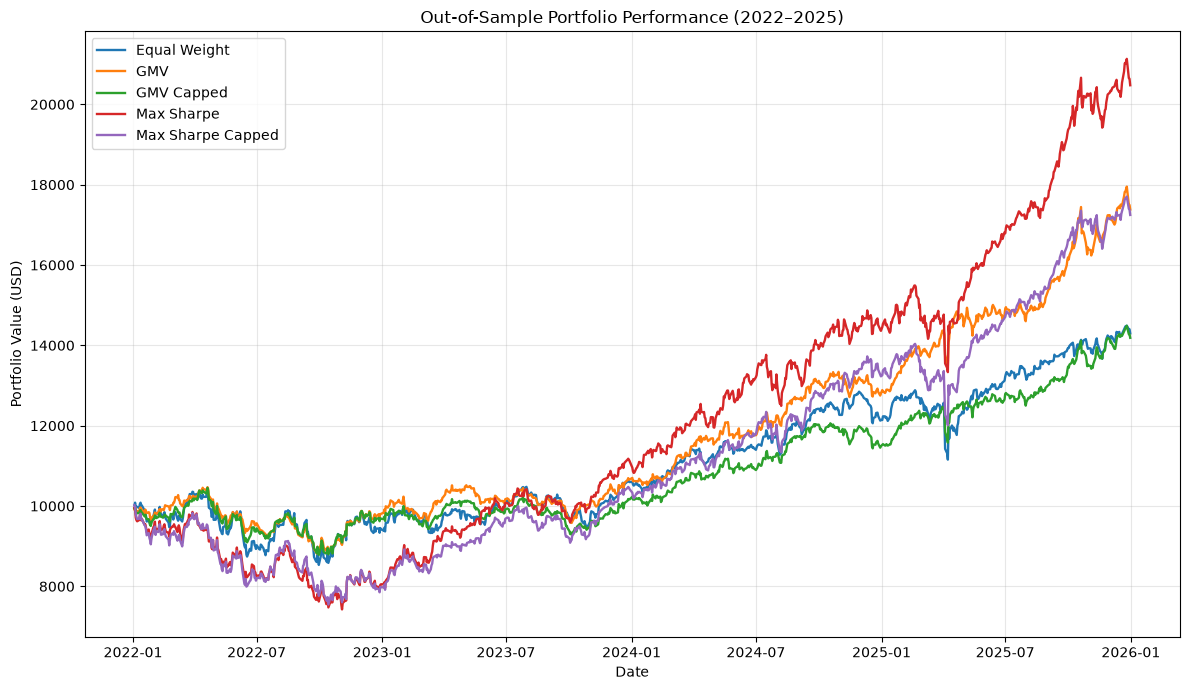

In [80]:
plt.figure(figsize=(12, 7))

for name in wealth.columns:
    plt.plot(
        wealth.index,
        wealth[name],
        label=name,
        linewidth=1.7
    )

plt.title("Out-of-Sample Portfolio Performance (2022–2025)")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (USD)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [81]:
# Risk-free rate during the testing period
rf_test = (
    treasury["DGS3MO"]
    .ffill()
    .shift(1)
    .reindex(test_portfolios.index, method="ffill")
)

assert rf_test.notna().all()

# Approximate daily risk-free rates
rf_daily = rf_test / 252

# Daily excess returns
excess_returns = test_portfolios.sub(rf_daily, axis=0)

# Drawdown calculations
drawdowns = wealth.div(
    wealth.cummax().clip(lower=initial_capital)
) - 1

# CVaR: average loss in the worst 5% of days
cvar_95 = test_portfolios.apply(
    lambda r: -r[r <= r.quantile(0.05)].mean()
)

# Performance summary
performance = pd.DataFrame({
    "Cumulative Return": wealth.iloc[-1] / initial_capital - 1,
    "CAGR": (wealth.iloc[-1] / initial_capital) ** (
        252 / len(test_portfolios)
    ) - 1,
    "Volatility": test_portfolios.std() * np.sqrt(252),
    "Sharpe": (
        excess_returns.mean()
        / excess_returns.std()
    ) * np.sqrt(252),
    "Max Drawdown": drawdowns.min(),
    "CVaR 95%": cvar_95
})

display(performance.sort_values("Sharpe", ascending=False))

,Cumulative Return,CAGR,Volatility,Sharpe,Max Drawdown,CVaR 95%
GMV,0.738272,0.149023,0.112131,0.922179,-0.157714,0.015687
Max Sharpe,1.047589,0.197288,0.166176,0.915157,-0.257425,0.022932
Max Sharpe Capped,0.724705,0.146763,0.159038,0.677622,-0.246834,0.022516
GMV Capped,0.418793,0.091865,0.108905,0.477287,-0.159708,0.015410
Equal Weight,0.429924,0.094011,0.142827,0.407470,-0.176708,0.020476


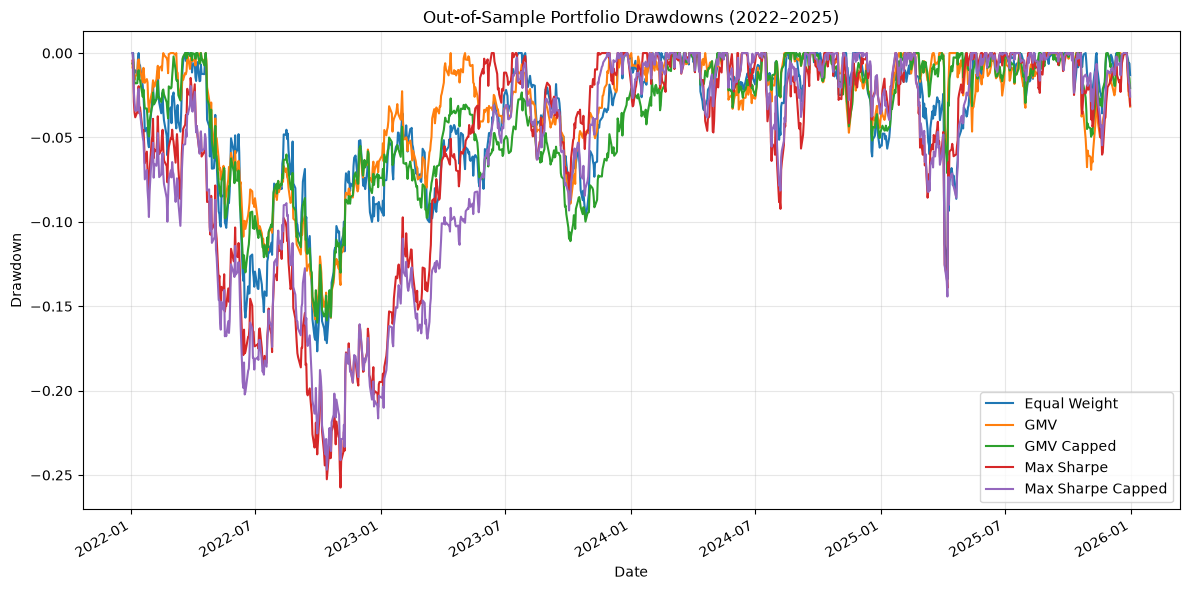

In [ ]:
drawdowns.plot(figsize=(12, 6), linewidth=1.5)

plt.title("Out-of-Sample Portfolio Drawdowns (2022–2025)")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()